In [1]:
from pathlib import Path 
import os
import dotenv
dotenv.load_dotenv()
os.chdir(Path(os.getenv("PYTHONPATH")).expanduser())

In [2]:
import pandas as pd
import time
import numpy as np
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from skorch import NeuralNetRegressor
import torch
import torch.nn as nn
from src.model.ESN import ESNRegressor

In [3]:
df = pd.read_pickle('data/lorenz_data.pkl')
df.drop(columns=["dt_min", "t_max"], inplace=True)
df.head()

,t,x,y,z
0,0.000,-7.906697,-14.129764,-16.306456
1,0.001,-7.968928,-14.465952,-16.151253
2,0.002,-8.033898,-14.803325,-15.992904
3,0.003,-8.101592,-15.141956,-15.831328
4,0.004,-8.171996,-15.481917,-15.666437


In [4]:
STRIDE = 100
df_strides = df[ ::STRIDE ].reset_index(drop=True)

In [5]:
df_strides.head()

,t,x,y,z
0,0.0,-7.906697,-14.129764,-16.306456
1,0.1,-24.672225,-42.914606,35.172661
2,0.2,-10.285805,23.156058,48.685025
3,0.3,10.837283,18.620737,42.387750
4,0.4,8.634182,0.248069,41.103149


In [6]:
df_strides[100:105]

,t,x,y,z
100,10.0,5.621907,7.848892,21.957250
101,10.1,8.172017,11.064759,22.585364
102,10.2,10.855023,12.750135,27.747833
103,10.3,10.888821,8.897440,32.231589
104,10.4,7.908417,4.722127,30.117574


In [7]:
df_strides = df_strides[100:].reset_index(drop=True)
df_strides.head()

,t,x,y,z
0,10.0,5.621907,7.848892,21.957250
1,10.1,8.172017,11.064759,22.585364
2,10.2,10.855023,12.750135,27.747833
3,10.3,10.888821,8.897440,32.231589
4,10.4,7.908417,4.722127,30.117574


In [8]:
rng = np.random.default_rng(0)
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
data = df_strides.to_numpy(dtype=np.float32)


In [9]:
from src.data import LorenzWindowViewDataset, ToSkorchXY
from src.util import build_windows, split_indices
from torch.utils.data import DataLoader

series = df_strides[["x", "y", "z"]].to_numpy(dtype=np.float32) 
dev_series = series[:10000]    # (T, 3)
D = dev_series.shape[1]        # 3
WARM, XLEN = 10, 100
windows = build_windows(dev_series, warm_length=WARM, x_length=XLEN)   # (N, W+X+1, 3) view
N = windows.shape[0]

# --- split into *indices* (not materialized arrays) ---
train_idx, val_idx = split_indices(N, train_ratio=0.8, seed=42)

mu  = windows[train_idx].reshape(-1, D).mean(axis=0).astype(np.float32)
sd  = windows[train_idx].reshape(-1, D).std(axis=0).astype(np.float32)
sd  = np.where(sd == 0.0, 1.0, sd)  # guard against zeros

train_ds = LorenzWindowViewDataset(windows, train_idx, WARM, XLEN, standardize=True, mean=mu, std=sd)
val_ds  = LorenzWindowViewDataset(windows, val_idx,  WARM, XLEN, standardize=True, mean=mu, std=sd)


train_loader = DataLoader(train_ds, batch_size=4, shuffle=True,  num_workers=0, pin_memory=False)
val_loader  = DataLoader(val_ds,  batch_size=4, shuffle=False, num_workers=0, pin_memory=False)


train_ds = ToSkorchXY(LorenzWindowViewDataset(
    window_view=windows, indices=train_idx, warm_length=WARM, x_length=XLEN,
    standardize=False
))
val_ds = ToSkorchXY(LorenzWindowViewDataset(
    window_view=windows, indices=val_idx, warm_length=WARM, x_length=XLEN,
    standardize=False
))


net = NeuralNetRegressor(
    ESNRegressor,
    module__input_size=3,
    module__output_size=3,
    module__reservoir_size=700,
    module__leak=0.9,
    module__spectral_radius=1.0,
    module__input_scale=0.9,
    module__bias_scale=0.0,
    module__sparsity=0.05,
    module__activation='tanh',
    module__seed=42,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    optimizer__lr=2e-3,
    optimizer__weight_decay=1e-4,   # 0.0001
    max_epochs=25,
    batch_size=64,
    train_split=None,               # no internal val split
    iterator_train__shuffle=False,  # keep time order
    device=device,
    verbose=0,
)

# Train with skorch
#net.fit(train_ds, y=None)

'''
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.05, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 0.9, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 1000, 'module__leak': 0.7, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.003, 'module__spectral_radius': 0.7, 'module__sparsity': 0.03, 'module__reservoir_size': 500, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.001, 'module__spectral_radius': 1.0, 'module__sparsity': 0.02, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.001, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.001, 'module__spectral_radius': 0.85, 'module__sparsity': 0.02, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.001, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 500, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 32}
{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 300, 'module__leak': 0.9, 'module__input_scale': 0.9, 'max_epochs': 25, 'batch_size': 16}
'''

"\n{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.05, 'module__reservoir_size': 700, 'module__leak': 0.9, 'module__input_scale': 0.9, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 0.7, 'module__sparsity': 0.05, 'module__reservoir_size': 1000, 'module__leak': 0.9, 'module__input_scale': 1.2, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.002, 'module__spectral_radius': 1.0, 'module__sparsity': 0.03, 'module__reservoir_size': 1000, 'module__leak': 0.7, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.0001, 'optimizer__lr': 0.003, 'module__spectral_radius': 0.7, 'module__sparsity': 0.03, 'module__reservoir_size': 500, 'module__leak': 0.9, 'module__input_scale': 0.6, 'max_epochs': 25, 'batch_size': 64}\n{'optimizer__weight_decay': 0.001, 'optimizer__lr': 0.001

In [10]:
# --- PREREQS (already built earlier) ------------------------------------------
# series:         np.ndarray (T, D) in ORIGINAL scale (float32)
# wins:           sliding_window_view(series, TOTAL=WARM+XLEN+1, axis=0)  -> (N, TOTAL, D)
# train_idx, val_idx: index arrays into wins (contiguous split recommended)
# mu, sd:         per-feature train-only mean/std (float32), shape (D,)
# WARM, XLEN:     warm and x lengths (e.g., 10, 100)

import time
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from skorch import NeuralNetRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_squared_error


def ds_to_arrays(ds):
    Xs, Ys = [], []
    for i in range(len(ds)):
        X_i, y_i = ds[i]
        Xs.append(X_i.numpy())
        Ys.append(y_i.numpy())
    return np.stack(Xs, 0), np.stack(Ys, 0)

# standardize ToConcatWarmWindowView outputs on the fly
def ds_to_arrays_std(ds, mu, sd):
    Xs, Ys = [], []
    for i in range(len(ds)):
        X_i, y_i = ds[i]             # original scale tensors
        X_i = (X_i.numpy() - mu) / sd
        y_i = (y_i.numpy() - mu) / sd
        Xs.append(X_i); Ys.append(y_i)
    return np.stack(Xs, 0), np.stack(Ys, 0)

# Return STANDARDIZED predictions
def rollout_std(est, start_window_orig, steps):
    cur = (start_window_orig - mu) / sd
    preds_std = []
    for _ in range(steps):
        y_next_std = est.predict(cur[None, ...]).astype(np.float32)[0]
        preds_std.append(y_next_std)
        cur = np.concatenate([cur[1:], y_next_std[None, :]], axis=0)
    return np.stack(preds_std, axis=0)  # <-- standardized

X_train, y_train = ds_to_arrays_std(train_ds, mu, sd)
X_val,   y_val   = ds_to_arrays_std(val_ds,   mu, sd)

# fit search exactly as you have it...
net.fit(X_train, y_train)

# original-space metrics
from sklearn.metrics import mean_squared_error
def inv(z): return z * sd + mu




In [11]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error



# 10-step rollout (STANDARDIZED)
abs_i0 = int(val_idx[0])
start_window_orig = windows[abs_i0, :WARM+XLEN, :]
K = 10
preds_std = rollout_std(net, start_window_orig, K)
gt_std = (dev_series[abs_i0 + WARM + XLEN : abs_i0 + WARM + XLEN + K] - mu) / sd


print(f"{K}-step rollout MSE (std):", mean_squared_error(gt_std, preds_std))
print("per-dim MSE:", mean_squared_error(gt_std, preds_std, multioutput="raw_values"))
print("R² per dim:", r2_score(gt_std, preds_std, multioutput="raw_values"))


10-step rollout MSE (std): 0.00971026811748743
per-dim MSE: [0.0050865  0.00938146 0.01466285]
R² per dim: [0.99185634 0.9807273  0.9846438 ]


In [12]:
# 10-step rollout (STANDARDIZED)
abs_i0 = int(val_idx[0])
start_window_orig = windows[abs_i0, :WARM+XLEN, :]
K_50 = 50
preds_std_50 = rollout_std(net, start_window_orig, K_50)
gt_std_50 = (dev_series[abs_i0 + WARM + XLEN : abs_i0 + WARM + XLEN + K_50] - mu) / sd


print(f"{K_50}-step rollout MSE (std):", mean_squared_error(gt_std_50, preds_std_50))
print("per-dim MSE:", mean_squared_error(gt_std_50, preds_std_50, multioutput="raw_values"))
print("R² per dim:", r2_score(gt_std_50, preds_std_50, multioutput="raw_values"))

50-step rollout MSE (std): 0.7261496186256409
per-dim MSE: [0.34136468 0.47212684 1.3649575 ]
R² per dim: [ 0.63376623  0.5012134  -0.26511335]


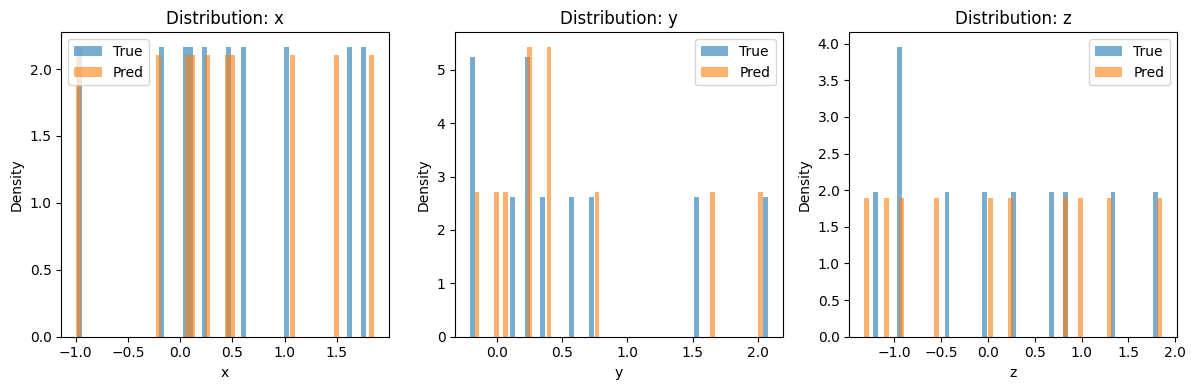

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# assume y_pred and y_true are in ORIGINAL scale, shape (N, 3)
axes = ['x', 'y', 'z']

plt.figure(figsize=(12, 4))
for i, a in enumerate(axes):
    plt.subplot(1, 3, i+1)
    plt.hist(gt_std[:, i], bins=60, alpha=0.6, label='True', density=True)
    plt.hist(preds_std[:, i], bins=60, alpha=0.6, label='Pred', density=True)
    plt.title(f'Distribution: {a}')
    plt.xlabel(a)
    plt.ylabel('Density')
    plt.legend()
plt.tight_layout()
plt.show()

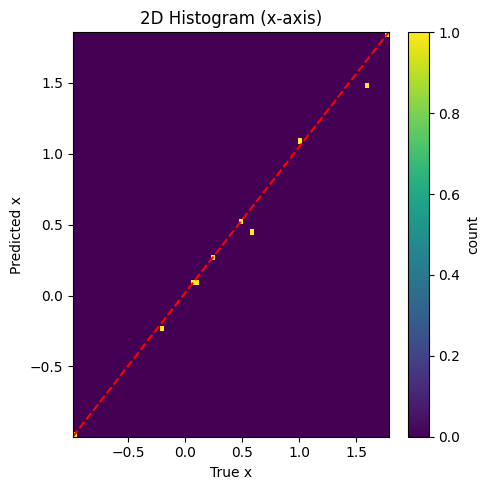

In [14]:
plt.figure(figsize=(5,5))
plt.hist2d(gt_std[:,0], preds_std[:,0], bins=80, cmap='viridis')
plt.xlabel("True x")
plt.ylabel("Predicted x")
plt.title("2D Histogram (x-axis)")
plt.colorbar(label='count')
plt.plot([gt_std[:,0].min(), gt_std[:,0].max()],
         [preds_std[:,0].min(), preds_std[:,0].max()], 'r--')
plt.tight_layout()
plt.show()

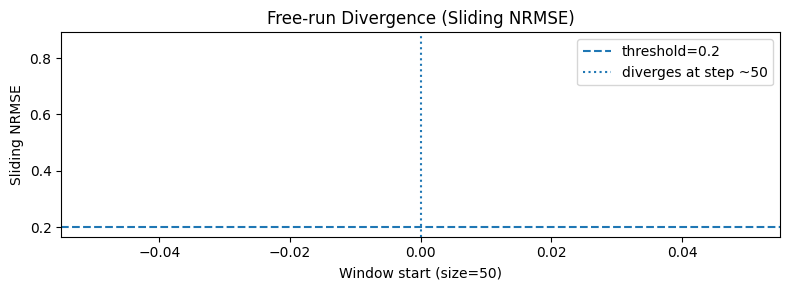


=== Divergence diagnostics ===
Aligned length : 50
Diverges at    : 50 steps (≈ 100.0% of rollout)

Pre-divergence metrics:
     K = 50.0000
   MSE = 0.7261
  RMSE = 0.8521
   MAE = 0.5951
    R2 = 0.2900

(No post-divergence segment — model stayed below threshold.)


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def rollout_diagnostics(y_true, y_pred, window=200, threshold=0.2, plot=True):
    """
    y_true: (K, D) ground truth segment aligned to the rollout start
    y_pred: (K, D) model rollout (same scale as y_true)
    window: sliding window length for NRMSE
    threshold: divergence threshold on NRMSE
    plot: whether to draw the NRMSE curve and threshold line

    Returns: dict with
      - 'aligned_len', 'diverges_at' (int or None), 'nrmse_series' (np.array)
      - 'pre'  : {'K','MSE','RMSE','MAE','R2'}  (if divergence found, up to divergence; else full)
      - 'post' : {'K','MSE','RMSE','MAE','R2'}  (if divergence found)
    """
    # --- align lengths safely ---
    K = min(len(y_true), len(y_pred))
    if K == 0:
        raise ValueError("Empty y_true/y_pred after alignment.")
    yt = np.asarray(y_true[:K], dtype=np.float32)
    yp = np.asarray(y_pred[:K], dtype=np.float32)

    # --- compute sliding NRMSE ---
    W = min(window, K)
    nrmse = []
    for s in range(0, K - W + 1):
        seg_t = yt[s:s+W]
        seg_p = yp[s:s+W]
        rmse = np.sqrt(np.mean((seg_t - seg_p)**2))
        denom = np.std(seg_t) + 1e-8
        nrmse.append(rmse / denom)
    nrmse = np.array(nrmse)  # length K-W+1

    # --- find divergence point (index in rollout steps) ---
    diverges_at = None
    if nrmse.size > 0:
        hits = np.where(nrmse > threshold)[0]
        if hits.size > 0:
            # convert window start index -> last index included in that window
            diverges_at = int(hits[0] + W)  # first step AFTER a window that exceeded threshold

    # --- helper to compute summary metrics over a slice ---
    def _metrics(a, b):
        mse = float(mean_squared_error(a, b))
        rmse = float(np.sqrt(mse))
        mae = float(mean_absolute_error(a, b))
        r2  = float(r2_score(a, b))
        return dict(K=len(a), MSE=mse, RMSE=rmse, MAE=mae, R2=r2)

    # --- pre/post segments ---
    stats_pre = _metrics(yt[:diverges_at], yp[:diverges_at]) if diverges_at else _metrics(yt, yp)
    stats_post = None
    if diverges_at and diverges_at < K:
        stats_post = _metrics(yt[diverges_at:], yp[diverges_at:])

    # --- optional plot ---
    if plot and nrmse.size > 0:
        plt.figure(figsize=(8,3))
        plt.plot(nrmse)
        plt.axhline(threshold, linestyle='--', label=f'threshold={threshold}')
        if diverges_at:
            # show vertical line at the window index corresponding to divergence
            plt.axvline(diverges_at - W, linestyle=':', label=f'diverges at step ~{diverges_at}')
        plt.xlabel(f"Window start (size={W})")
        plt.ylabel("Sliding NRMSE")
        plt.title("Free-run Divergence (Sliding NRMSE)")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return dict(
        aligned_len=K,
        diverges_at=diverges_at,      # int or None
        nrmse_series=nrmse,
        pre=stats_pre,
        post=stats_post,
        window=W,
        threshold=threshold,
    )

# Assuming you already computed:
# long_preds: (k, D) rollout (scaled or original)
# y_true    : (k, D) aligned ground truth in the SAME scale

diag = rollout_diagnostics(gt_std_50, preds_std_50, window=50, threshold=0.2, plot=True)

print("\n=== Divergence diagnostics ===")
print(f"Aligned length : {diag['aligned_len']}")
print(f"Diverges at    : {diag['diverges_at']} steps (≈ {diag['diverges_at']/len(gt_std_50)*100:.1f}% of rollout)")
print("\nPre-divergence metrics:")
for k,v in diag['pre'].items():
    print(f"  {k:>4s} = {v:.4f}" if isinstance(v,(int,float)) else f"  {k}: {v}")

if diag['post']:
    print("\nPost-divergence metrics:")
    for k,v in diag['post'].items():
        print(f"  {k:>4s} = {v:.4f}" if isinstance(v,(int,float)) else f"  {k}: {v}")
else:
    print("\n(No post-divergence segment — model stayed below threshold.)")



In [16]:
K = 10
thr = 0.2
horizons, nrmse10, skill10 = [], [], []

for i in val_idx:
    start_window = windows[i, :WARM+XLEN, :]
    preds = rollout_std(net, start_window, K)                          # std scale
    gt    = (dev_series[i+WARM+XLEN:i+WARM+XLEN+K] - mu) / sd

    # NRMSE@50
    rmse = np.sqrt(mean_squared_error(gt, preds))
    nrmse = rmse / (np.std(gt) + 1e-8)
    nrmse10.append(nrmse)

    # horizon via your diagnostics with window=50 (single value)
    d = rollout_diagnostics(gt, preds, window=min(50, K), threshold=thr, plot=False)
    horizons.append(d['diverges_at'] or K)

    # persistence baseline
    last = (start_window[-1] - mu) / sd
    base = np.repeat(last[None, :], K, axis=0)
    mse_m = mean_squared_error(gt, preds)
    mse_b = mean_squared_error(gt, base)
    skill10.append(1 - mse_m / (mse_b + 1e-12))

print(f"Success rate @10 (NRMSE<{thr}): {(np.mean(np.array(nrmse10)<thr))*100:.1f}%")
print(f"Median NRMSE@10: {np.median(nrmse10):.3f}")
print(f"Median Skill@10 vs persistence: {np.median(skill10):.3f}")
print(f"Median horizon H: {np.median(horizons)} steps")


ValueError: Found input variables with inconsistent numbers of samples: [7, 10]